# Fundamentals of Neural Networks

Neural networks are the engine behind everything in **Level 7** of this roadmap — Transformers, LLMs, diffusion models. This note builds the foundation from first principles: what a neuron computes, why non-linear activations are essential, how backpropagation trains a network, and what the same model looks like hand-written in NumPy and written in PyTorch.

> **Prerequisites:** Linear algebra (Level 2, Section 4), gradient descent (Level 2, Section 6), and the bias-variance tradeoff (Level 2, Section 8) — neural networks are gradient descent applied to a composition of linear maps.

## 1. From Perceptron to Multi-Layer Perceptron

A single **artificial neuron** computes a weighted sum plus bias, passed through an activation $\phi$:

$$
y = \phi(w_1 x_1 + w_2 x_2 + \dots + w_n x_n + b) = \phi(\mathbf{w}^\top \mathbf{x} + b)
$$

A **Multi-Layer Perceptron (MLP)** stacks these into layers, where each layer's output feeds the next:

$$
\mathbf{h}^{(1)} = \phi\left(W^{(1)}\mathbf{x} + \mathbf{b}^{(1)}\right), \quad
\hat{y} = \phi_{out}\left(W^{(2)}\mathbf{h}^{(1)} + \mathbf{b}^{(2)}\right)
$$

- Each $W^{(l)}$ is a learned weight matrix; each $\mathbf{b}^{(l)}$ a learned bias vector.
- **Width** = neurons per layer, **depth** = number of layers. Networks with many layers are called *deep* — hence deep learning.
- The **universal approximation theorem** says an MLP with one hidden layer can approximate any continuous function — but depth makes it exponentially more parameter-efficient.

Why an activation at all? Without $\phi$, a stack of linear layers collapses: $W^{(2)}(W^{(1)}\mathbf{x}) = (W^{(2)}W^{(1)})\mathbf{x}$ is still just one linear map. **Non-linearity is what buys expressive power.**

## 2. Activation Functions

| Activation | Formula | Range | Notes |
|---|---|---|---|
| **Sigmoid** | $\sigma(z) = \frac{1}{1+e^{-z}}$ | $(0, 1)$ | Classic output for binary probability; saturates → vanishing gradients |
| **Tanh** | $\tanh(z)$ | $(-1, 1)$ | Zero-centered sigmoid; still saturating |
| **ReLU** | $\max(0, z)$ | $[0, \infty)$ | The modern default; cheap, non-saturating for $z>0$; "dead ReLU" if $z<0$ always |
| **Leaky ReLU / GELU** | variants | $\mathbb{R}$ | GELU is standard inside Transformers (Level 7) |

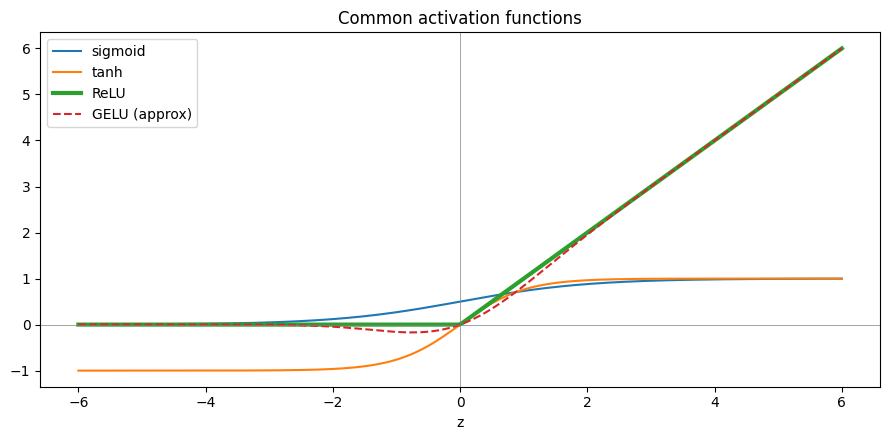

In [1]:
import numpy as np
import matplotlib.pyplot as plt

z = np.linspace(-6, 6, 300)
plt.figure(figsize=(9, 4.5))
plt.plot(z, 1 / (1 + np.exp(-z)), label="sigmoid")
plt.plot(z, np.tanh(z), label="tanh")
plt.plot(z, np.maximum(0, z), label="ReLU", lw=3)
plt.plot(z, 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z**3))),
         "--", label="GELU (approx)")
plt.axhline(0, color="gray", lw=0.5); plt.axvline(0, color="gray", lw=0.5)
plt.title("Common activation functions")
plt.xlabel("z"); plt.legend()
plt.tight_layout()
plt.show()

## 3. Why Depth Beats Linear: The XOR Problem

XOR is not linearly separable — no single line can separate the classes. A perceptron (linear model) provably fails on it; an MLP with one hidden layer solves it easily. This 1969 observation (Minsky & Papert) stalled AI for years — until backpropagation made training hidden layers practical in the 1980s.

| $x_1$ | $x_2$ | XOR |
|:---:|:---:|:---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

## 4. Backpropagation in One Paragraph

Training = minimize a **loss** $L(\hat{y}, y)$ by gradient descent (Level 2, Section 6). Backpropagation is just the **chain rule** applied efficiently: the error signal flows backwards through the network, and each layer's gradients are computed from the layer above:

$$
\frac{\partial L}{\partial W^{(1)}} = \frac{\partial L}{\partial \hat{y}} \cdot \frac{\partial \hat{y}}{\partial \mathbf{h}^{(1)}} \cdot \frac{\partial \mathbf{h}^{(1)}}{\partial W^{(1)}}
$$

One forward pass stores intermediate values; one backward pass reuses them to get every gradient. That's it — the rest is engineering (see Karpathy's *Zero to Hero* series in the resources below, where you build this from scratch).

## 5. A Neural Network from Scratch (NumPy)

Before touching a framework, implement one by hand — forward pass, backprop, and a training loop. This is the single best way to understand what PyTorch automates for you.

**Network:** 2 inputs → 4 hidden (tanh) → 1 output (sigmoid), trained with binary cross-entropy on XOR.

In [2]:
import numpy as np

# ---------- Data: XOR ----------
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

# ---------- Initialize ----------
rng = np.random.RandomState(42)
W1 = rng.normal(0, 1, (2, 4)); b1 = np.zeros((1, 4))
W2 = rng.normal(0, 1, (4, 1)); b2 = np.zeros((1, 1))

def forward(X):
    h = np.tanh(X @ W1 + b1)          # hidden layer
    o = 1 / (1 + np.exp(-(h @ W2 + b2)))  # sigmoid output
    return h, o

def bce_loss(o, y):  # binary cross-entropy
    eps = 1e-9
    return -np.mean(y * np.log(o + eps) + (1 - y) * np.log(1 - o + eps))

lr, epochs = 0.5, 8000
history = []
for epoch in range(epochs):
    # ---- forward ----
    h, o = forward(X)
    history.append(bce_loss(o, y))
    # ---- backward (chain rule) ----
    d_o = -(y / (o + 1e-9) - (1 - y) / (1 - o + 1e-9)) / len(X)   # dL/do
    d_s = o * (1 - o)                                              # sigmoid'
    delta2 = d_o * d_s                                             # dL/dz2
    dW2 = h.T @ delta2; db2 = delta2.sum(0)
    delta1 = (delta2 @ W2.T) * (1 - h ** 2)                        # tanh'
    dW1 = X.T @ delta1; db1 = delta1.sum(0)
    # ---- update ----
    W2 -= lr * dW2; b2 -= lr * db2
    W1 -= lr * dW1; b1 -= lr * db1

print("Final loss:", round(history[-1], 5))
_, out = forward(X)
print("Predictions:", out.ravel().round(3), "-> classes:", (out > 0.5).astype(int).ravel())
print("Targets:    ", y.ravel().astype(int))

Final loss: 0.00059
Predictions: [0.    0.999 0.999 0.001] -> classes: [0 1 1 0]
Targets:     [0 1 1 0]


The network learned XOR — something no linear model can do. The hidden layer internally learned two intermediate features (essentially OR and AND-like patterns) that make the problem linearly separable in the hidden space. That is the whole trick of deep learning: **learned representations**.

## 6. The Same Network in PyTorch

PyTorch automates everything above: `autograd` computes the gradients, the optimizer applies them. This is the workflow you will use for the rest of the roadmap — CNNs, Transformers, and fine-tuning LLMs (Level 7) are all `nn.Module`s like this one.

In [3]:
import torch
import torch.nn as nn

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

X_t = torch.tensor([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_t = torch.tensor([[0.], [1.], [1.], [0.]])

model = nn.Sequential(
    nn.Linear(2, 8), nn.Tanh(),
    nn.Linear(8, 1), nn.Sigmoid(),
)
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(2000):
    pred = model(X_t)
    loss = loss_fn(pred, y_t)
    optimizer.zero_grad()   # clear old gradients
    loss.backward()         # backprop (autograd)
    optimizer.step()        # update weights

with torch.no_grad():
    final = model(X_t)
print("Final loss:", round(loss.item(), 5))
print("Predictions:", final.ravel().numpy().round(3))
print("Classes:    ", (final > 0.5).long().ravel().numpy())

PyTorch version: 2.14.1+cpu


Final loss: 0.00031
Predictions: [0. 1. 1. 0.]
Classes:     [0 1 1 0]


## 7. A Real Problem: Non-Linear Decision Boundary

Two moons is the standard "linear model fails here" dataset. Let's train a slightly bigger MLP and visualize the decision boundary it learns.

Training accuracy: 99.3%  (final loss 0.0158)


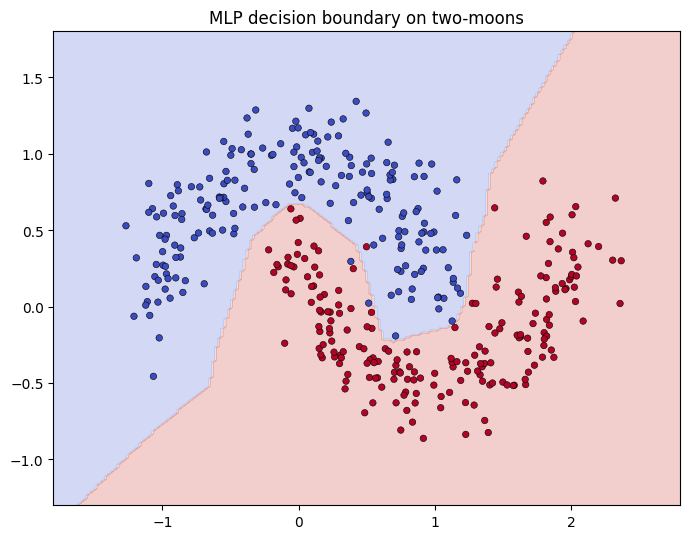

In [4]:
from sklearn.datasets import make_moons

X_m, y_m = make_moons(n_samples=400, noise=0.18, random_state=7)
X_mt = torch.tensor(X_m, dtype=torch.float32)
y_mt = torch.tensor(y_m, dtype=torch.float32).unsqueeze(1)

torch.manual_seed(1)
model = nn.Sequential(
    nn.Linear(2, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
loss_fn = nn.BCEWithLogitsLoss()          # numerically stable sigmoid + BCE
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(600):
    logits = model(X_mt)
    loss = loss_fn(logits, y_mt)
    optimizer.zero_grad(); loss.backward(); optimizer.step()

acc = ((logits > 0) == y_mt).float().mean().item()
print(f"Training accuracy: {acc:.1%}  (final loss {loss.item():.4f})")

# ---- decision boundary ----
xx, yy = np.meshgrid(np.linspace(-1.8, 2.8, 200), np.linspace(-1.3, 1.8, 200))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
with torch.no_grad():
    zz = (model(grid) > 0).float().numpy().reshape(xx.shape)

plt.figure(figsize=(7, 5.5))
plt.contourf(xx, yy, zz, alpha=0.25, cmap="coolwarm")
plt.scatter(X_m[:, 0], X_m[:, 1], c=y_m, cmap="coolwarm", s=22, edgecolor="k", lw=0.4)
plt.title("MLP decision boundary on two-moons")
plt.tight_layout()
plt.show()

## 8. Training Essentials (What Actually Goes Wrong)

| Symptom | Likely cause | Fix |
|---|---|---|
| Loss barely moves | Learning rate too small, dead ReLUs, unscaled inputs | Standardize features (Level 3, Section 3); raise LR; try Leaky ReLU |
| Loss explodes to NaN | Learning rate too large | Lower LR; gradient clipping |
| Perfect train, poor test | Overfitting (high variance) | More data, dropout, weight decay, early stopping — see **Bias-Variance Tradeoff (Level 2, Section 8)** |
| Great validation, poor production | Distribution shift, data leakage | See **Data Leakage (Level 3, Section 16)** |

**Practical defaults in 2026:** Adam/AdamW optimizer with LR around `1e-3`, standardized inputs, mini-batches of 32–256, and a validation split for early stopping. Use the GPU (`.to("cuda")`) when data or models grow — training on CPU is fine for everything in this note.

## 9. Where to Go Next

- **Andrej Karpathy — Neural Networks: Zero to Hero** ([YouTube playlist](https://www.youtube.com/playlist?list=PLAqhIrjkxbuWI23vo9l4_a6_60X5UPW5v)) — builds backprop, autograd, and a GPT from scratch. The best deep-learning foundation available.
- **PyTorch official tutorials** ([pytorch.org/tutorials](https://pytorch.org/tutorials/)) — 60-minute blitz, then training workflows.
- **3Blue1Brown — Neural networks** ([video series](https://www.youtube.com/playlist?list=PLZHQObOWTQDNU6R1_67000Dx_ZCJB-3pi)) — visual intuition for what networks learn.
- **Stanford CS231n** (CNNs) and **CS224n** (NLP) — the university courses, materials free online.
- Then continue to **Level 7.1** of this roadmap: Transformer architecture, attention, and the LLM stack.

**Key takeaways:** an MLP is layered linear maps with non-linear activations; backprop is the chain rule; frameworks automate the calculus, not the judgment. Everything in modern AI — from the network you just wrote to GPT-class models — still trains with this same forward/backward/update loop.